<table border=0 width="100%"><tr><td><p align="left"><img src="..\img\logo.png" align="left" width=300></p></td><td><font size=3><B>machine learning for stock prediction (Haichao Zheng)</B></font></td></tr></table>

today's topic
- strategy evaluation
- prediction tasks
- what is machine learning
- how to train a model
- how to train a linear regression model
- KNN

# strategy evaluation

In [1]:
import tushare as ts
import pandas as pd
import numpy as np
token = 'aa6d7dba75bcd6eccd5bbda27e0cf6cf56c4759ec767990bdb041575'
ts.set_token(token)
pro = ts.pro_api()

start_date='19950101'
end_date='20230505'

index_daily = pro.index_daily(ts_code='000001.SH', start_date=start_date, end_date=end_date)
index_daily.trade_date = pd.DatetimeIndex(index_daily.trade_date)
index_daily.set_index("trade_date",inplace=True)
index_daily.sort_index(inplace=True)

index_train = index_daily["1995":"2015"]
index_test = index_daily["2015":"2023"]

case: Trading strategy evaluation - sma

In [2]:
index_train.shape

(5097, 10)

In [3]:
index_test.shape

(2027, 10)

# prediction tasks

- text classification
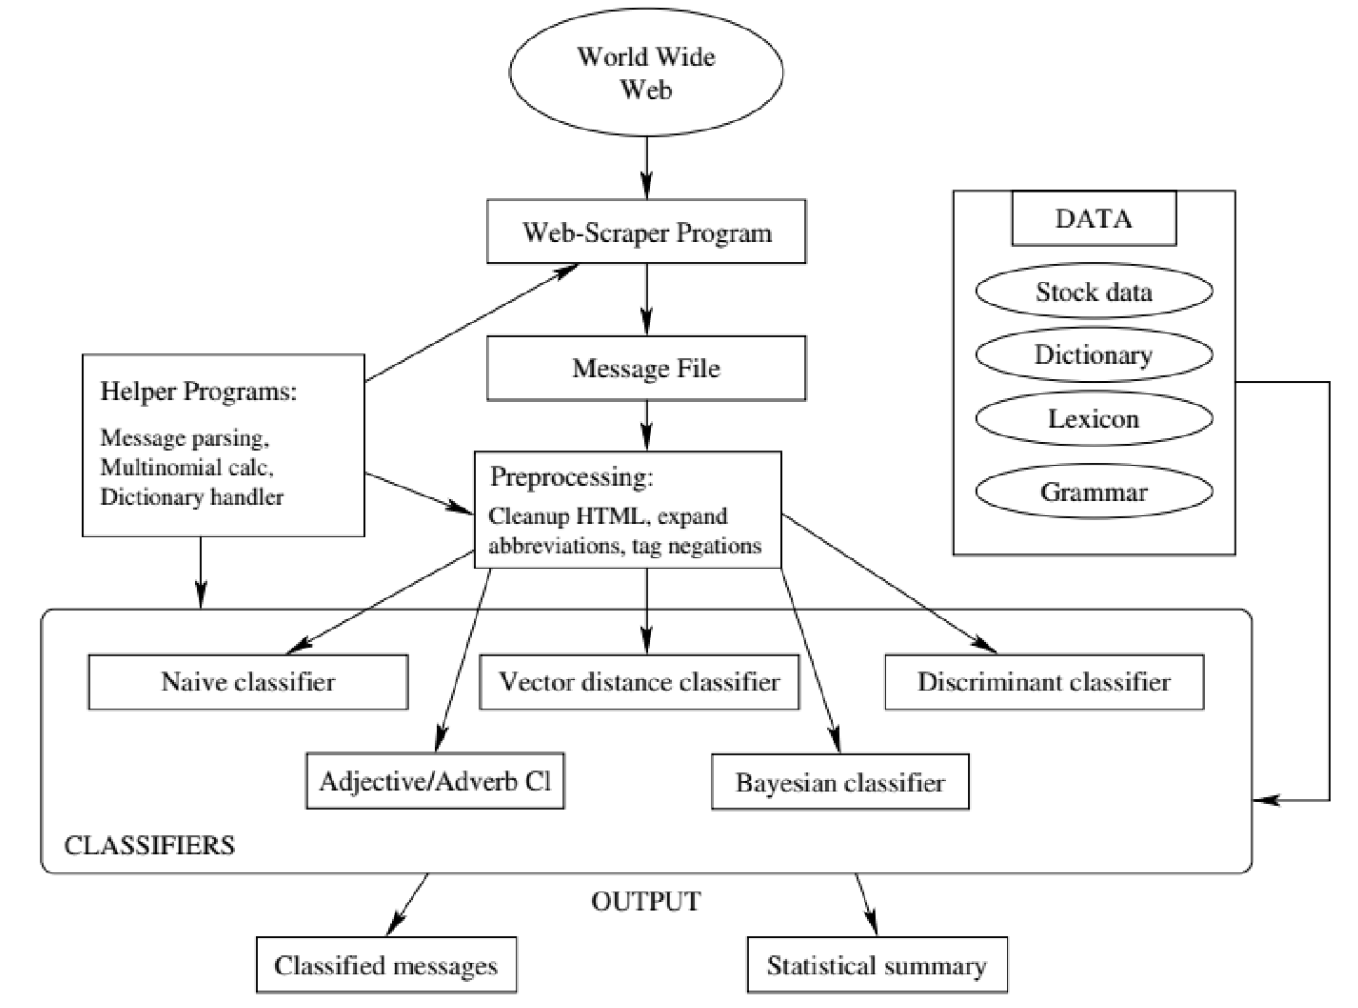

我们经常被垃圾邮件困扰，如下图所示：

<img src="../img/spam.png" align='left' height="500" width="600"/>

如何做垃圾邮件过滤器呢？

<img src="../img/rulebased.png" align='left' height="300" width="400"/>

* 步骤1：首先看看垃圾邮件通常是什么样子。你可能会注意到一些单词或短语(如“邀请函”、“培训班”、“offer”和“important information”)在垃圾邮件中经常出现。
* 步骤2：您可以为每个模式编写一个检测算法，如果检测到许多这样的模式，您的程序将把电子邮件标记为垃圾邮件。
* 步骤3：测试您的程序，并重复步骤1和步骤2，直到足够好为止。

由于这个这些规则不太明显，您的程序很可能会变成一长串复杂的规则——很难维护。

相比之下，基于机器学习技术的垃圾邮件过滤器，则通过检测垃圾邮件示例中与非垃圾邮件示例相比出现的异常的单词模式，自动学习哪些单词和短语是垃圾邮件的**良好预测特征**（例如提高“邀请函”、“培训班”、“offer”和“important information”等词汇的权重）。这样，程序要短得多，易于维护。

<img src="../img/mlbased.png" align='left' height="300" width="400"/>

对文本做分类一个典型代表是朴素贝叶斯分类器

can we classify text with GPT?

- stock movement prediction

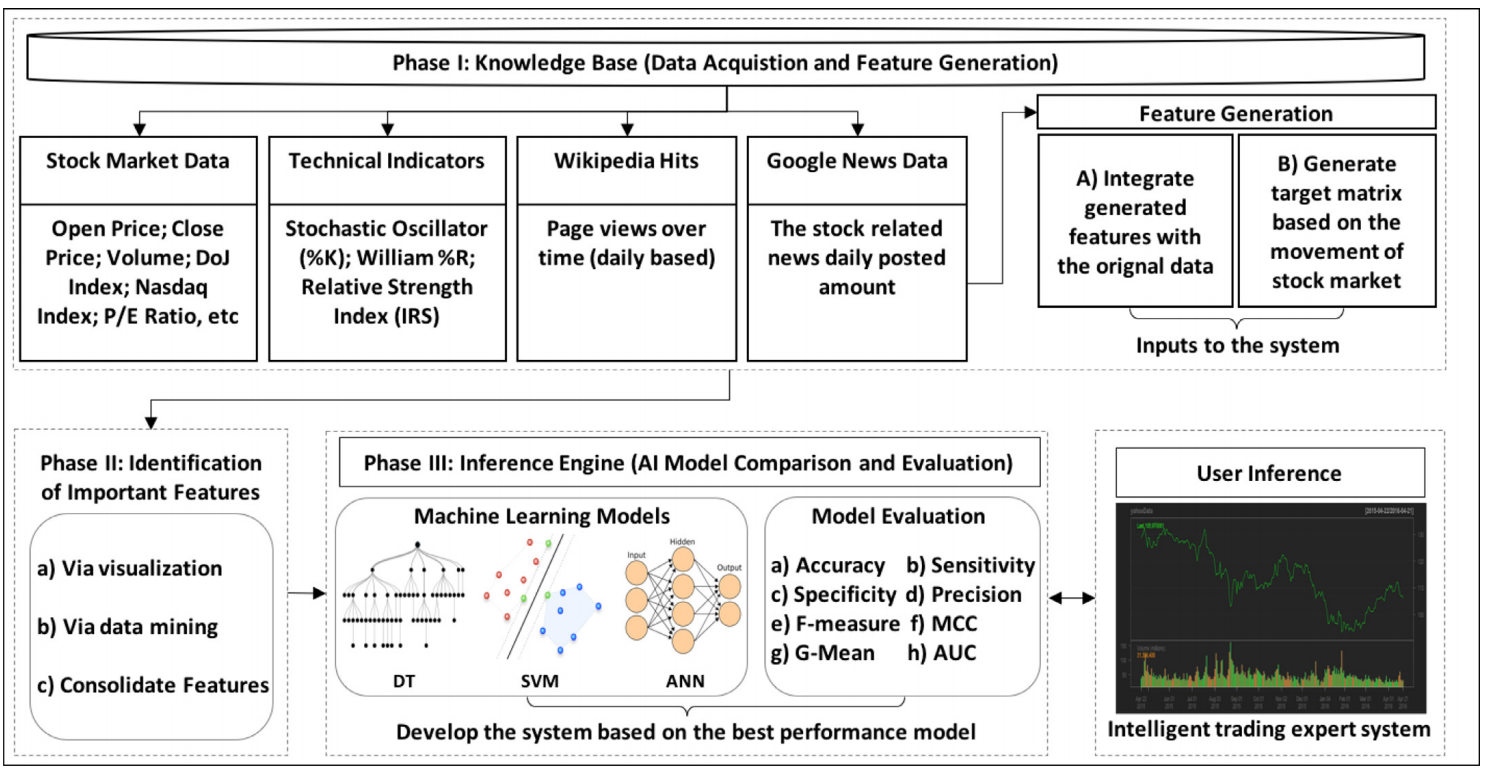

讨论：
- 使用技术指标做指数波动方向预测有什么局限吗？

can you list more prediction tasks?

# what is machine learning

Machine Learning is the science (and art) of programming computers so they can learn from data
More engineering-oriented one
A computer program is said to learn from experience E with respect to some task T and some performance measure P, if its performance on T, as measured by P, improves with experience E. 
* Task
* Experience
* Performance

## Supervised machine learning

机器学习任务有多种类型，这里我们重点提：有监督的机器学习和无监督的机器学习。在有监督学习中，训练数据有标签。一个典型的监督学习任务是分类。例如，我们可以通过带有标签（垃圾邮件还是正常邮件）的电子邮件，训练一个垃圾邮件过滤器。

<img src="../img/supervised.png" align='left' height="300" width="400"/>

sentiment analysis
text 
- 这个电影很好看。
- 这个电影太糟糕了。

labels - positive or negative

regression - 

另一个典型的有监督学习任务是预测一个目标数值，例如汽车的价格，给定一组称为预测器的特性(里程、年龄、品牌等)。这类任务称为回归。

<img src="../img/regression.png" align='left' height="300" width="400"/>

监督学习的主要任务是学习一个模型，模型的一般形式为决策函数：$ Y = f(X)$或者条件概率分布$ P(Y|X)$。监督学习又可以分为生成方法和判别方法。
* 生成方法：由数据学习联合概率分布$P(X,Y)$,然后求出条件概率分布$P(Y|X)$作为预测的模型。$ P(A \mid B) = \frac{ P(B \mid A) P(A) }{P(B)}$ 

隐马尔科夫模型也是一类生成模型，其中的解码问题是典型的预测问题

* 判别方法：由数据直接学习决策函数$f(x)$作为预测的模型。代表方法：感知机，支持向量机，神经网络。

<img src="../img/supervised_learning.png" align='left' height="300" width="400"/>

## Unsupervised learning

无监督学习：在无监督学习中，训练数据是没有标记的。典型的应用包括：聚类、异常检测和新颖性检测、可视化和降维、关联规则学习

下面是一个t-SNE可视化的例子

<img src="../img/tsne.png" align='left' height="400" width="600"/>

## Reinforcement learning

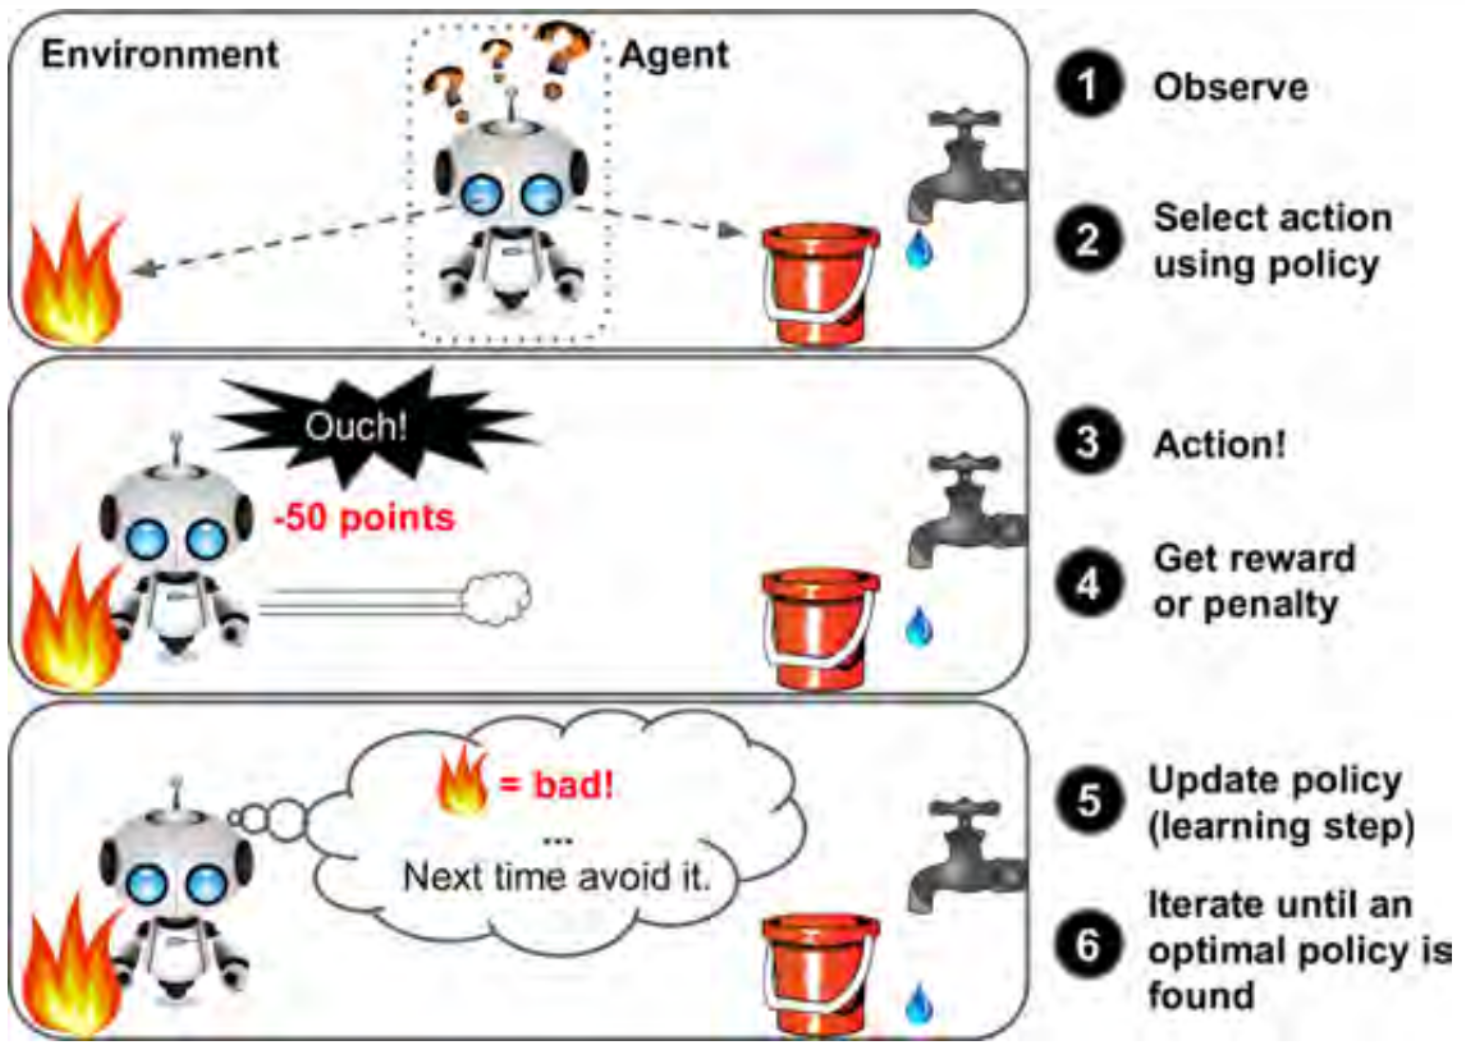

# how to train a model?
## prediction model and loss function

Machine learning ≈constructs a mapping function

<img src="../img/mapping_function.png" align='left' height="400" width="600"/>

give some training samples $(_xi, y_i)$,1 ≤ i ≤ N, where $x_i$  is the input, and  $y_i$  is the target, let the computer automatically find a mapping function $f(·)$ to establish the relationship between $x$ and $y$.

<img src="../img/training.png" align='left' height="400" width="600"/>

Three elements of machine learning

<img src="../img/elements_ml.png" align='left' height="400" width="600"/>

Parameters learning (training models)

<img src="../img/parameter_learning.png" align='left' height="400" width="600"/>

## gradient descent

In mathematics and optimization, a gradient represents the rate of change of a function with respect to its variables. It is a vector that points in the direction of the steepest ascent of the function. The gradient provides information about both the direction and magnitude of the function's maximum rate of change.

To compute the gradient of a function, you need to calculate the partial derivatives of the function with respect to each of its variables.


Let's consider a simple function f(x, y) = x^2 + 2y. We want to compute the gradient of this function.

Identify the variables: In this case, we have two variables x and y.

- Compute the partial derivative with respect to x (denoted as ∂f/∂x):
∂f/∂x = 2x

- Compute the partial derivative with respect to y (denoted as ∂f/∂y):
∂f/∂y = 2

Assemble the gradient vector:
The gradient vector ∇f = (∂f/∂x, ∂f/∂y) = (2x, 2)

For example, if we want to evaluate the gradient at the point (x = 3, y = 1), we substitute the values into the gradient vector:
∇f(x=3, y=1) = (2(3), 2) = (6, 2)

The resulting gradient vector (6, 2) indicates that at the point (x = 3, y = 1), the function f(x, y) has the steepest ascent in the x-direction and a constant rate of change in the y-direction.

参考资料：http://zh.gluon.ai/chapter_optimization/gd-sgd.html
本节课我们使用了《动手学深度学习》的部分代码和文档，特此注明并表示感谢！

梯度下降的一般原理可以用下图展示。即从一个初始的参数，沿着函数下降的方向逐步更新参数。

<img src="../img/sgd.png"  height="300" width="400"/>

什么才是下降最快的方向呢？我们先以简单的一维梯度下降为例，解释梯度下降算法可能降低目标函数值的原因。假设连续可导的函数$f: \mathbb{R} \rightarrow \mathbb{R}$的输入和输出都是标量。给定绝对值足够小的数$\epsilon$，根据泰勒展开公式，我们得到以下的近似：

$$f(x + \epsilon) \approx f(x) + \epsilon f'(x) .$$

这里$f'(x)$是函数$f$在$x$处的梯度。一维函数的梯度是一个标量，也称导数。

接下来，找到一个常数$\eta > 0$，使得$\left|\eta f'(x)\right|$足够小，那么可以将$\epsilon$替换为$-\eta f'(x)$并得到

$$f(x - \eta f'(x)) \approx f(x) -  \eta f'(x)^2.$$

如果导数$f'(x) \neq 0$，那么$\eta f'(x)^2>0$，所以$f(x - \eta f'(x)) \lesssim f(x).$

下面我们以目标函数$f(x)=x^2$为例来看一看梯度下降是如何工作的。虽然我们知道最小化$f(x)$的解为$x=0$，这里依然使用这个简单函数来观察$x$是如何被迭代的。首先，导入本节实验所需的包或模块。

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt
import math
import numpy as np

接下来使用$x=10$作为初始值，并设$\eta=0.2$。使用梯度下降对$x$迭代10次，可见最终$x$的值较接近最优解。

In [11]:
def gd(eta):
    x = 10
    results = [x]
    for i in range(10):
        x = x - eta * 2 * x  # f(x) = x * x的导数为f'(x) = 2 * x
        results.append(x)
    print('epoch 10, x:', x)
    return results

res = gd(01.1)
res

epoch 10, x: 61.917364224000096


[10,
 -12.0,
 14.400000000000002,
 -17.280000000000005,
 20.736000000000008,
 -24.883200000000013,
 29.859840000000023,
 -35.83180800000004,
 42.998169600000054,
 -51.59780352000007,
 61.917364224000096]

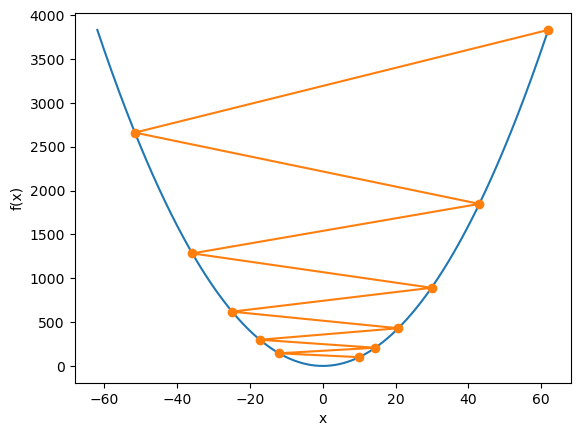

In [12]:
def show_trace(res):
    n = max(abs(min(res)), abs(max(res)), 10)
    f_line = np.arange(-n, n, 0.1)
    plt.plot(f_line, [x * x for x in f_line])
    plt.plot(res, [x * x for x in res], '-o')
    plt.xlabel('x')
    plt.ylabel('f(x)')

show_trace(res)

上述梯度下降算法中的正数$\eta$通常叫作学习率。这是一个超参数，需要人工设定。如果使用过小的学习率，会导致$x$更新缓慢从而需要更多的迭代才能得到较好的解。

下面展示使用学习率$\eta=0.05$时自变量$x$的迭代轨迹。可见，同样迭代10次后，当学习率过小时，最终$x$的值依然与最优解存在较大偏差。

尝试一下其他更大一些的学习率？

在了解了一维梯度下降之后，我们再考虑一种更广义的情况：目标函数的输入为向量，输出为标量。假设目标函数$f: \mathbb{R}^d \rightarrow \mathbb{R}$的输入是一个$d$维向量$\boldsymbol{x} = [x_1, x_2, \ldots, x_d]^\top$。目标函数$f(\boldsymbol{x})$有关$\boldsymbol{x}$的梯度是一个由$d$个偏导数组成的向量：

$$\nabla_{\boldsymbol{x}} f(\boldsymbol{x}) = \bigg[\frac{\partial f(\boldsymbol{x})}{\partial x_1}, \frac{\partial f(\boldsymbol{x})}{\partial x_2}, \ldots, \frac{\partial f(\boldsymbol{x})}{\partial x_d}\bigg]^\top.$$


为表示简洁，我们用$\nabla f(\boldsymbol{x})$代替$\nabla_{\boldsymbol{x}} f(\boldsymbol{x})$。梯度中每个偏导数元素$\partial f(\boldsymbol{x})/\partial x_i$代表着$f$在$\boldsymbol{x}$有关输入$x_i$的变化率。我们可能通过梯度下降算法来不断降低目标函数$f$的值：

$$\boldsymbol{x} \leftarrow \boldsymbol{x} - \eta \nabla f(\boldsymbol{x}).$$

同样，其中$\eta$（取正数）称作学习率。

## batch gradient descent, stochastic GD, and mini-batch GD

假设一个目标函数是训练数据集中有关各个样本的损失函数的平均。设$L_i(\boldsymbol{x})$是有关索引为$i$的训练数据样本的损失函数，$n$是训练数据样本数，$\boldsymbol{x}$是模型的参数向量，那么目标函数定义为$L(\boldsymbol{x}) = \frac{1}{n} \sum_{i = 1}^n f_i(\boldsymbol{x}).$

目标函数在$\boldsymbol{x}$处的梯度计算为$$\nabla L(\boldsymbol{x}) = \frac{1}{n} \sum_{i = 1}^n \nabla L_i(\boldsymbol{x}).$$
如果使用梯度下降，每次自变量迭代的计算开销为$\mathcal{O}(n)$，它随着$n$线性增长。因此，当训练数据样本数很大时，梯度下降每次迭代的计算开销很高。

随机梯度下降（stochastic gradient descent，SGD）减少了每次迭代的计算开销。在随机梯度下降的每次迭代中，我们随机均匀采样的一个样本索引$i\in\{1,\ldots,n\}$，并计算梯度$\nabla f_i(\boldsymbol{x})$来迭代$\boldsymbol{x}$：

$$\boldsymbol{x} \leftarrow \boldsymbol{x} - \eta \nabla f_i(\boldsymbol{x}).$$

这里$\eta$同样是学习率。可以看到每次迭代的计算开销从梯度下降的$\mathcal{O}(n)$降到了常数$\mathcal{O}(1)$。值得强调的是，随机梯度$\nabla f_i(\boldsymbol{x})$是对梯度$\nabla f(\boldsymbol{x})$的无偏估计：

$$E_i \nabla f_i(\boldsymbol{x}) = \frac{1}{n} \sum_{i = 1}^n \nabla f_i(\boldsymbol{x}) = \nabla f(\boldsymbol{x}).$$

这意味着，平均来说，随机梯度是对梯度的一个良好的估计。

我们可以通过重复采样（sampling with replacement）或者不重复采样（sampling without replacement）得到一个小批量中的各个样本。前者允许同一个小批量中出现重复的样本，后者则不允许如此，且更常见。对于这两者间的任一种方式，都可以使用

<img src="../img/batch_sgd.png"  height="500" width="700"/>

# how to update the parameters for a linear regeression model

## Closed-form solution to minimize the cost function

Closed-form solution to minimize the cost function 

<img src="../img/linear_solution.png"  height="400" width="600"/>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression

In [ ]:
def load_data():
    gdp_satisfaction = pd.read_csv("gdp_satisfaction.csv",index_col = "Country")
    X = gdp_satisfaction.values[:,0]
    y = gdp_satisfaction.values[:,1]
    return gdp_satisfaction,X,y

In [ ]:
data,X,y = load_data()
data.sort_values(by = "Life satisfaction")

In [ ]:
data.columns

In [ ]:
# Visualize the data
data.plot(kind='scatter', x="GDP per capita", y='Life satisfaction')
plt.show()

In [ ]:
# Select a linear model
model = LinearRegression()
#X = np.log10(X)
# 
X = (X - np.mean(X))/np.std(X)
X = X[:,np.newaxis]
y = y[:,np.newaxis]
# Train the model
model.fit(X, y)
model.coef_

In [ ]:
np.linalg.inv(X.T.dot(X)).dot(X.T).dot(y)

In [ ]:
# predict the satisfactions based on the trained model
y_predict = model.predict(X)
plt.plot(X,y_predict, "r",label = "predict")
plt.scatter(X,y,label = "raw data")
plt.xlabel("gdp_log10")
plt.ylabel("satisfaction")
plt.legend()
plt.savefig("gdp.png")
plt.show()

## stochastic gradient descent

损失函数（loss function）

$$ f(x_i,y_i) = \frac {1}{2} (w*x_i +b - y_i)^2$$

根据上面定义的损失函数，写一个随机梯度下降函数gd，更新参数w和b：

$$w \leftarrow w - \eta f'(w)$$

$$b \leftarrow b - \eta f'(b)$$

In [ ]:
def gd(eta,w,b,x,y):
    
    
    
    
    
    return w, b

In [ ]:
# 初始化
import numpy as np
w,b = np.random.randn(2)
w,b

In [ ]:
# train the model
eta = 0.01
for i in range(100000):
    sample = np.random.choice(len(y))
    x = X[sample][0]
    real_y = y[sample][0]
    w, b = gd(eta, w, b, x, real_y)

In [ ]:
w,b

除了随机梯度下降，我们也可以使用
- batch gradient descent
- mini batch gradient descent

# KNN（K-Nearest Neighbors）

## what is KNN

KNN（K-Nearest Neighbors）是一种基本的监督学习算法，用于分类和回归任务。KNN模型基于实例之间的相似性度量，通过对最近邻居的投票或平均值来进行预测。

在KNN模型中，训练数据集由特征向量和对应的标签组成。在进行预测时，模型会计算待预测样本与训练数据集中各个样本之间的距离，通常使用欧氏距离或曼哈顿距离等作为距离度量标准。

KNN模型的工作原理如下：

- 选择一个合适的K值，即要考虑的最近邻居的数量。
- 对于待预测样本，计算其与训练数据集中每个样本之间的距离。
- 根据距离的大小，选择最近的K个样本作为最近邻居。
- 对于分类任务，根据最近邻居的标签进行投票，将得票最多的类别作为预测结果。
- 对于回归任务，根据最近邻居的标签进行平均或加权平均，得到预测结果。

KNN模型的特点：

- 简单且易于理解和实现。
- 对于少量训练样本和特征维度较低的问题表现较好。
- 对异常值敏感，因为预测结果受最近邻居的影响较大。
- 随着数据量的增加，计算距离的时间和内存消耗较大。
- 没有要学习的参数（没有显式的学习过程）


- 欧氏距离 $d$ 为：
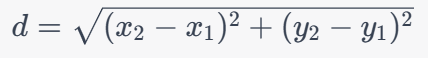
其中，$x_1$、$y_1$ 表示第一个点的坐标，$x_2$、$y_2$ 表示第二个点的坐标。通过计算坐标差的平方和再开方，即可得到欧氏距离$d$的值。


- 曼哈顿距离 = |x2 - x1| + |y2 - y1|


在KNN模型中选择适当的距离度量方式是很重要的，因为它会影响模型的性能和结果。以下是一些常见的距离度量方式以及选择方法：

- 欧氏距离（Euclidean distance）：KNN模型默认使用距离公式，适用于连续型特征的度量，常用于大多数情况。欧式距离假设所有的特征对模型的贡献是平等的，并且在处理具有相同重要性的特征时通常有效。

- 曼哈顿距离（Manhattan distance）：适用于特征空间是离散的情况，或者在特征具有明显不同的度量单位时使用。

## which K is better for KNN
假设我们有以下三个训练样本数据：

- 训练样本1：特征向量 [1, 2]，标签为 "A"。
- 训练样本2：特征向量 [2, 3]，标签为 "B"。
- 训练样本3：特征向量 [4, 4]，标签为 "A"。  

请给出使用欧式距离，做KNN模型.

现在我们要预测一个新的测试样本，特征向量为 [3, 3]，我们将使用KNN模型来进行分类。

当k=1和k=3时，结果相同吗？给出计算步骤？

选择合适的K值对KNN模型的分类效果至关重要。K值的选择可以通过交叉验证、网格搜索或经验法则来确定。

不同大小的K值会对分类效果产生影响：

- 当K值较小（如K=1）时，模型更加敏感和容易受到噪声的影响。模型可能会对个别样本点的分类错误敏感，容易出现过拟合的情况。这意味着模型可能对训练数据中的噪声点作出过度反应，导致分类边界过于复杂，可能会出现局部性较强的分类结果。

- 当K值较大时，模型更加稳定和平滑。通过考虑更多的邻居样本，模型可以更好地捕捉数据的整体分布和结构。这可以降低噪声的影响，减少过拟合的风险。然而，当K值过大时，模型可能会丧失一些局部细节和敏感性，导致分类边界过于平滑，可能无法很好地适应训练数据中的局部特征。

因此，选择合适的K值要考虑数据集的特点、噪声水平以及模型的复杂度需求。一般而言，较小的K值适合简单的数据集和较少的噪声，而较大的K值适合复杂的数据集和较多的噪声。此外，还可以通过交叉验证等方法来评估不同K值下的模型性能，并选择在验证集上表现最佳的K值。

## train KNN with KNeighborsClassifier

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


# 训练样本特征向量
X_train = [[1, 2], [2, 3], [4, 4]]
# 训练样本标签
y_train = ['A', 'B', 'A']

# 创建KNN模型并指定k值为1
knn = KNeighborsClassifier(n_neighbors=3, metric='manhattan')
# 使用训练数据拟合模型
knn.fit(X_train, y_train)

# 待预测的测试样本
X_test = [[3, 3],[2,2]]
# 预测测试样本的标签
y_pred = knn.predict(X_test)

# 输出预测结果
print(y_pred)

## K Neighbors and their voting results

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

# 训练样本特征向量
X_train = [[1, 2], [2, 3], [4, 4],[5,5]]
# 训练样本标签
y_train = ['A', 'B', 'A','B']

# 创建KNN模型并指定k值为3
knn = KNeighborsClassifier(n_neighbors=3)
# 使用训练数据拟合模型
knn.fit(X_train, y_train)

# 待预测的测试样本
X_test = [[3, 3], [2, 3], [5, 5]]

# 遍历每个样本
for i, x in enumerate(X_test):
    # 获取测试样本的最近邻居的索引和距离
    
    
    
    

# caculate voting consistency
- 最大类别的投票数占总的投票数的比例

In [3]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

# 训练样本特征向量
X_train = [[1, 2], [2, 3], [4, 4],[5,5]]
# 训练样本标签
y_train = ['A', 'B', 'A','B']

# 创建KNN模型并指定k值为3
knn = KNeighborsClassifier(n_neighbors=3)
# 使用训练数据拟合模型
knn.fit(X_train, y_train)

# 待预测的测试样本
X_test = [[3, 3], [2, 3], [5, 5]]

# 创建空的DataFrame
df = pd.DataFrame(columns=['样本', '类别A投票数', '类别B投票数', '投票一致性', '投票预测结果'])

# 遍历每个样本
for i, x in enumerate(X_test):
    # 获取测试样本的最近邻居的索引和距离
    distances, indices = knn.kneighbors([x])

    # 统计投票结果
    votes = {'A': 0, 'B': 0}
    for idx in indices[0]:
        label = y_train[idx]
        votes[label] += 1

    # 计算投票一致性
    
    
    
    
    
    
    # 添加信息到DataFrame
    df.loc[i] = [x, votes['A'], votes['B'], consistency, max_label]

# 打印DataFrame
df

,样本,类别A投票数,类别B投票数,投票一致性,投票预测结果
0,"[3, 3]",2,1,0.666667,B
1,"[2, 3]",2,1,0.666667,B
2,"[5, 5]",1,2,0.666667,B
